# GRN Analysis: Influencer Genes vs. Receiver Genes

Core quantity: **GRN = d v_X / d X ~= J_psi_x * (-B) * (J_psi_x^T J_psi_x)^(-1) * J_psi_x^T**

- **Column norm ||GRN[:, j]||**: total strength with which gene j influences the velocities of all other genes -> *Influencer / Master Regulator*
- **Row norm ||GRN[i, :]||**: total strength with which gene i's velocity is influenced by the global gene-expression state -> *Receiver / Target*
- **Diagonal entry GRN[i, i]**: self-regulation strength of gene i (positive = self-activation, negative = self-repression)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import networkx as nx
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

BIO_DIR = './bio_analysis'

DATASETS = {
    'mouse':     {'dir': 'mouse',     'label': 'Mouse Embryo',                 'color': '#e07b54'},
    'axoltl':    {'dir': 'axoltl',    'label': 'Axolotl Telencephalon Regen.', 'color': '#5b8dd9'},
    'zebrafish': {'dir': 'zebrafish', 'label': 'Zebrafish Embryo',             'color': '#57a773'},
}

def shorten(g):
    """Shorten axolotl-style gene names like 'SYMBOL | AMEX60DDxxxxxx'."""
    return g.split('|')[0].strip() if '|' in g else g

def load_grn_data(dname):
    d = DATASETS[dname]['dir']
    GRN = np.load(f'{BIO_DIR}/{d}/GRN_matrix.npy')   # (G, G)
    df  = pd.read_csv(f'{BIO_DIR}/{d}/driver_genes_ranking.csv')
    # The CSV is sorted by row-norm (regulatory_influence).
    # GRN rows/cols are in the original gene order.
    # Align: sort both by descending row-norm value to recover original indices.
    row_norms = np.linalg.norm(GRN, axis=1)
    col_norms = np.linalg.norm(GRN, axis=0)
    diag      = np.diag(GRN)
    grn_order = np.argsort(row_norms)[::-1]          # original GRN indices in rank order
    csv_order = df.sort_values('regulatory_influence', ascending=False).index
    # grn_order[k] is the GRN row/col index of the k-th ranked gene in the CSV
    gene_names_ranked = df.loc[csv_order, 'gene'].values   # gene names in rank order
    # Build lookup: gene name -> GRN index
    gene_to_idx = {gene_names_ranked[k]: grn_order[k] for k in range(len(gene_names_ranked))}
    idx_to_gene = {v: k for k, v in gene_to_idx.items()}
    # Build per-gene DataFrame with both metrics
    gene_df = pd.DataFrame({
        'gene':        [idx_to_gene[i] for i in range(len(row_norms))],
        'gene_short':  [shorten(idx_to_gene[i]) for i in range(len(row_norms))],
        'row_norm':    row_norms,
        'col_norm':    col_norms,
        'self_reg':    diag,
        'grn_idx':     np.arange(len(row_norms)),
    })
    return GRN, gene_df, gene_to_idx

datasets = {}
for dname in DATASETS:
    GRN, gene_df, gene_to_idx = load_grn_data(dname)
    datasets[dname] = {'GRN': GRN, 'gene_df': gene_df, 'gene_to_idx': gene_to_idx}
    print(f"{dname}: {len(gene_df)} genes, GRN {GRN.shape}, "
          f"col_norm max={gene_df['col_norm'].max():.3f} ({gene_df.loc[gene_df['col_norm'].idxmax(), 'gene_short']}), "
          f"row_norm max={gene_df['row_norm'].max():.3f} ({gene_df.loc[gene_df['row_norm'].idxmax(), 'gene_short']})")

mouse: 3000 genes, GRN (3000, 3000), col_norm max=3.267 (Fibin), row_norm max=5.187 (Gphn)
axoltl: 3000 genes, GRN (3000, 3000), col_norm max=0.226 (SCGN), row_norm max=0.406 (SLC1A3)
zebrafish: 3000 genes, GRN (3000, 3000), col_norm max=0.376 (si:dkey-26g8.5), row_norm max=0.997 (krt4)


## 1. Influencer vs. Receiver: Genome-Wide Scatter Plot

Four quadrants:
- Upper right: **Hub genes** - strongly regulate others and are strongly regulated by others
- Lower right: **Master regulators** - strongly influence others while being weakly regulated themselves
- Upper left: **Downstream targets** - strongly regulated but weak external output
- Lower left: **Bystanders** - weakly connected to the regulatory network

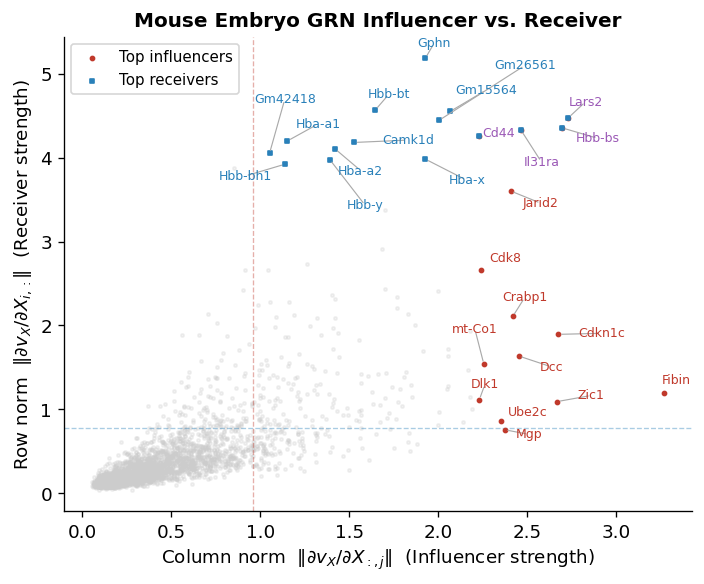

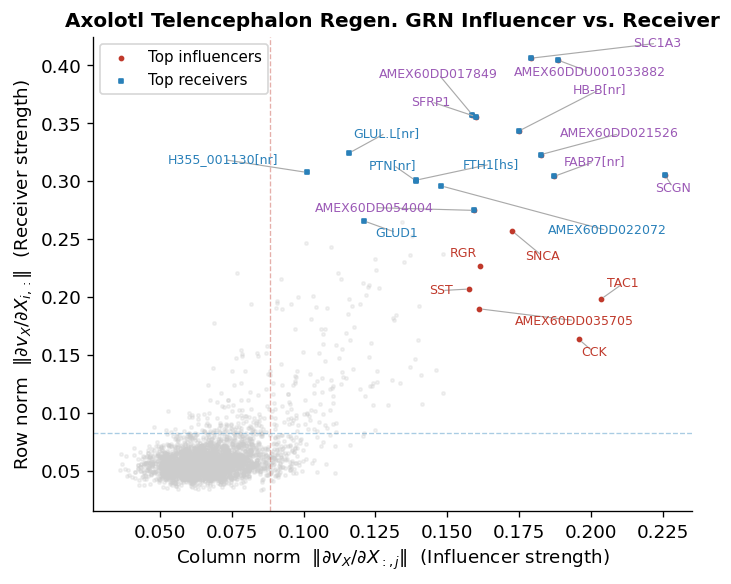

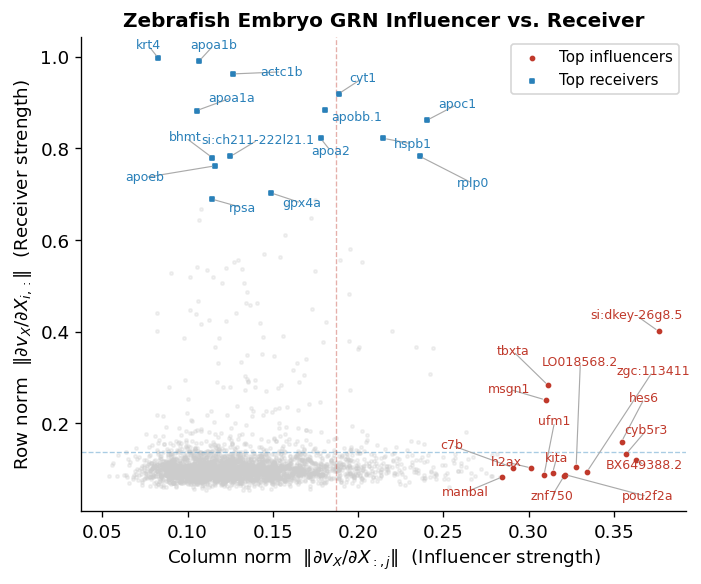

In [23]:
from adjustText import adjust_text

TOP_LABEL = 15   # label top-N in each axis

for dname, meta in DATASETS.items():
    gene_df = datasets[dname]['gene_df']
    col_q = gene_df['col_norm'].quantile(0.9)
    row_q = gene_df['row_norm'].quantile(0.9)

    fig, ax = plt.subplots(figsize=(6, 5))

    # Background points
    ax.scatter(gene_df['col_norm'], gene_df['row_norm'],
               s=4, alpha=0.25, color='#cccccc', zorder=1)

    # Top influencers (high col_norm)
    top_inf = gene_df.nlargest(TOP_LABEL, 'col_norm')
    ax.scatter(top_inf['col_norm'], top_inf['row_norm'],
               s=6, color='#c0392b', zorder=3, label='Top influencers')

    # Top receivers (high row_norm)
    top_rec = gene_df.nlargest(TOP_LABEL, 'row_norm')
    ax.scatter(top_rec['col_norm'], top_rec['row_norm'],
               s=6, color='#2980b9', zorder=3, label='Top receivers', marker='s')

    # Union of labeled genes; color: purple=hub, red=influencer-only, blue=receiver-only
    labeled = pd.concat([top_inf, top_rec]).drop_duplicates('gene')
    inf_genes = set(top_inf['gene'])
    rec_genes = set(top_rec['gene'])
    label_colors = [
        '#9b59b6' if (g in inf_genes and g in rec_genes)
        else '#c0392b' if g in inf_genes
        else '#2980b9'
        for g in labeled['gene']
    ]

    texts = [
        ax.text(row['col_norm'], row['row_norm'], row['gene_short'],
                fontsize=7.5, color=color, fontweight='medium', zorder=5)
        for (_, row), color in zip(labeled.iterrows(), label_colors)
    ]

    # Auto-repel labels and draw connector lines to original points
    adjust_text(
        texts,
        x=labeled['col_norm'].values,
        y=labeled['row_norm'].values,
        ax=ax,
        arrowprops=dict(arrowstyle='-', color='#aaaaaa', lw=0.7),
        expand=(1.5, 1.8),
        force_text=(0.5, 0.7),
        force_points=(0.3, 0.4),
        min_arrow_len=6,
    )

    ax.axvline(col_q, color='#c0392b', lw=0.8, ls='--', alpha=0.4)
    ax.axhline(row_q, color='#2980b9', lw=0.8, ls='--', alpha=0.4)
    ax.set_xlabel(r'Column norm  $\|\partial v_X / \partial X_{:,j}\|$  (Influencer strength)', fontsize=11)
    ax.set_ylabel(r'Row norm  $\|\partial v_X / \partial X_{i,:}\|$  (Receiver strength)', fontsize=11)
    ax.set_title(f"{meta['label']} GRN Influencer vs. Receiver", fontsize=12, fontweight='bold')
    ax.legend(fontsize=9, loc='best')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.savefig(f"{BIO_DIR}/{DATASETS[dname]['dir']}/influencer_vs_receiver.png", dpi=300, bbox_inches='tight')
    plt.show()

## 2. Top Influencer Genes (Ranked by Column Norm)

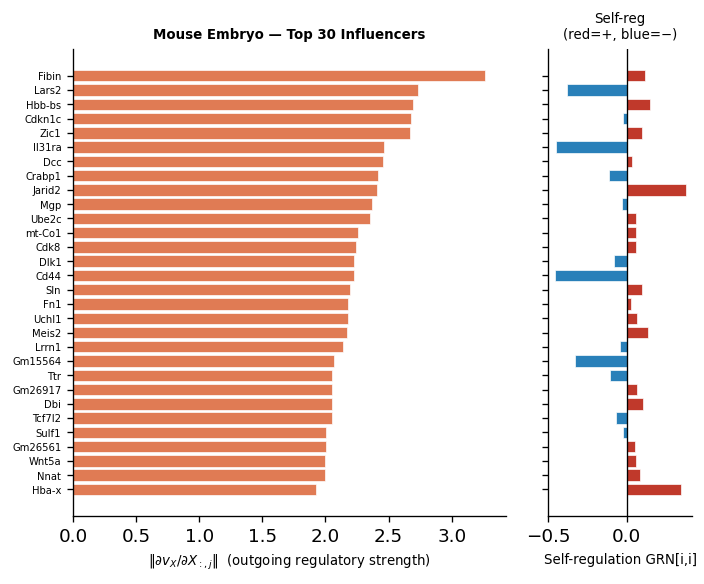

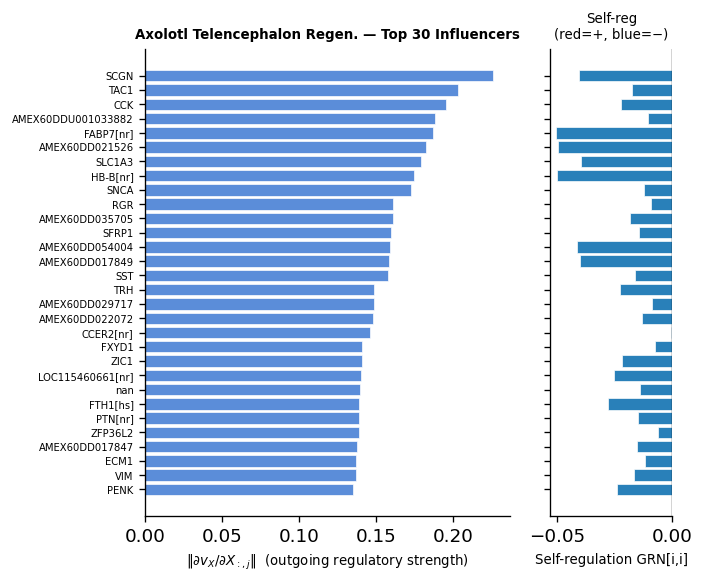

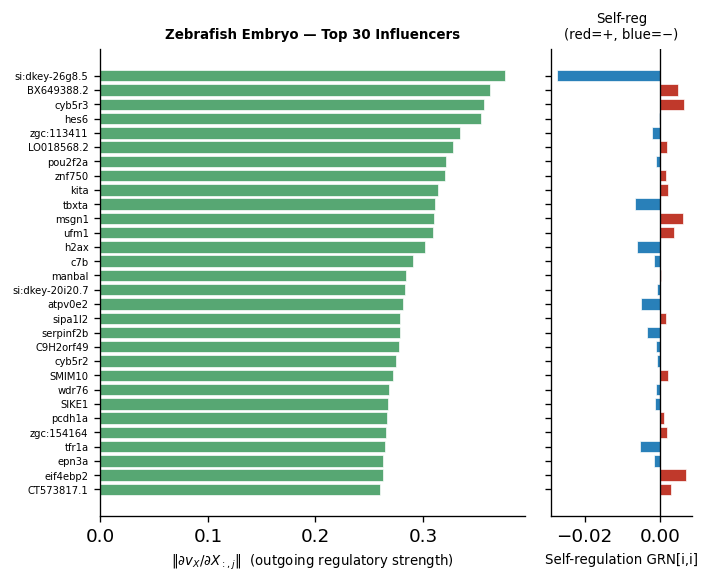

In [24]:
TOP_N = 30

for dname, meta in DATASETS.items():
    gene_df = datasets[dname]['gene_df']
    top = gene_df.nlargest(TOP_N, 'col_norm').copy().iloc[::-1]

    fig, axes = plt.subplots(1, 2, figsize=(6, 5), gridspec_kw={'width_ratios': [3, 1]})

    # Bar: col_norm
    ax = axes[0]
    colors = ['#c0392b' if v >= 0 else '#2980b9' for v in top['self_reg']]
    ax.barh(top['gene_short'], top['col_norm'], color=meta['color'],
            edgecolor='white', linewidth=0.4)
    ax.set_xlabel(r'$\|\partial v_X / \partial X_{:,j}\|$  (outgoing regulatory strength)', fontsize=8)
    ax.set_title(f"{meta['label']} — Top {TOP_N} Influencers", fontsize=8, fontweight='bold')
    ax.tick_params(axis='y', labelsize=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Self-regulation bar (signed)
    ax = axes[1]
    colors_sr = ['#c0392b' if v >= 0 else '#2980b9' for v in top['self_reg']]
    ax.barh(top['gene_short'], top['self_reg'], color=colors_sr,
            edgecolor='white', linewidth=0.4)
    ax.axvline(0, color='k', lw=0.8)
    ax.set_xlabel('Self-regulation GRN[i,i]', fontsize=8)
    ax.set_title('Self-reg\n(red=+, blue=−)', fontsize=8)
    ax.tick_params(axis='y', labelleft=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.tight_layout()
    plt.savefig(f"{BIO_DIR}/{DATASETS[dname]['dir']}/top_influencers.png", dpi=300, bbox_inches='tight')
    plt.show()

## 3. Top Receiver Genes (Ranked by Row Norm)

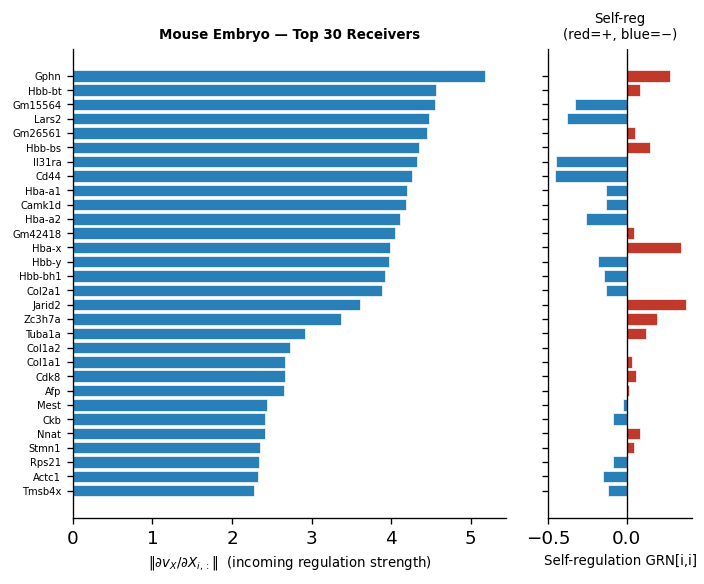

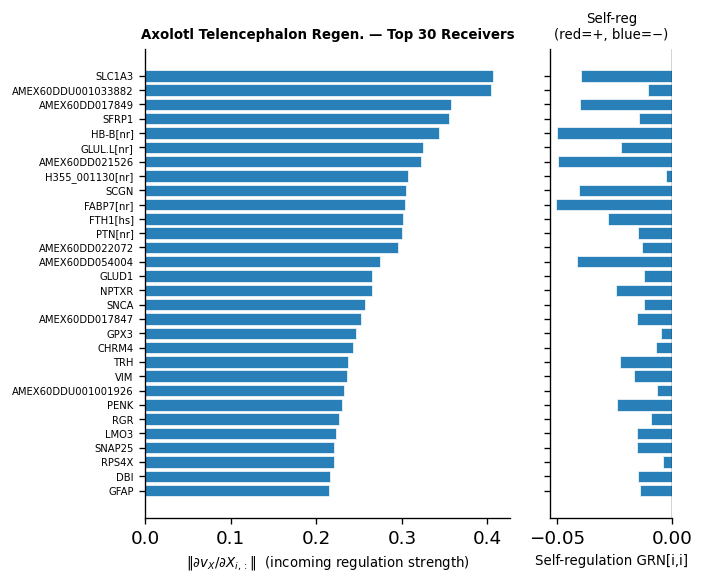

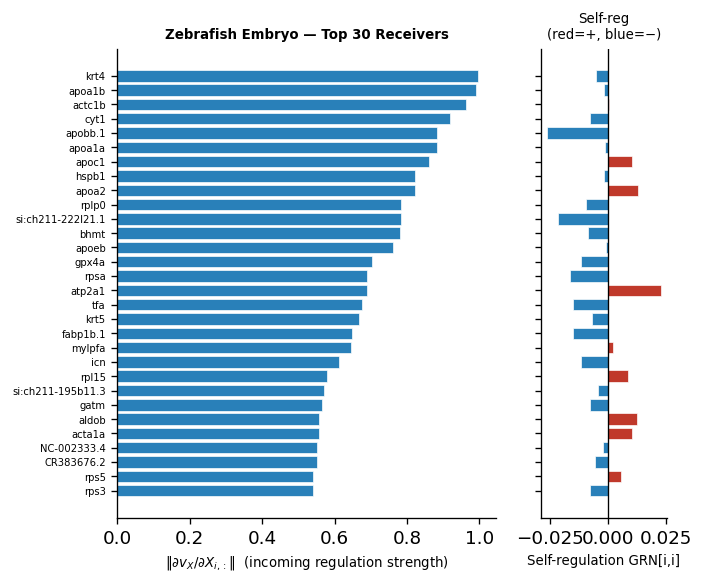

In [25]:
TOP_N = 30

for dname, meta in DATASETS.items():
    gene_df = datasets[dname]['gene_df']
    top = gene_df.nlargest(TOP_N, 'row_norm').copy().iloc[::-1]

    fig, axes = plt.subplots(1, 2, figsize=(6, 5), gridspec_kw={'width_ratios': [3, 1]})

    ax = axes[0]
    ax.barh(top['gene_short'], top['row_norm'], color='#2980b9',
            edgecolor='white', linewidth=0.4)
    ax.set_xlabel(r'$\|\partial v_X / \partial X_{i,:}\|$  (incoming regulation strength)', fontsize=8)
    ax.set_title(f"{meta['label']} — Top {TOP_N} Receivers", fontsize=8, fontweight='bold')
    ax.tick_params(axis='y', labelsize=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax = axes[1]
    colors_sr = ['#c0392b' if v >= 0 else '#2980b9' for v in top['self_reg']]
    ax.barh(top['gene_short'], top['self_reg'], color=colors_sr,
            edgecolor='white', linewidth=0.4)
    ax.axvline(0, color='k', lw=0.8)
    ax.set_xlabel('Self-regulation GRN[i,i]', fontsize=8)
    ax.set_title('Self-reg\n(red=+, blue=−)', fontsize=8)
    ax.tick_params(axis='y', labelleft=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.tight_layout()
    plt.savefig(f"{BIO_DIR}/{DATASETS[dname]['dir']}/top_receivers.png", dpi=300, bbox_inches='tight')
    plt.show()

## 4. GRN Submatrix: Top Influencers -> Top Receivers

Rows = receivers (regulated genes), columns = influencers (regulatory genes), color = sign and magnitude of d v_X[i] / d X[j].

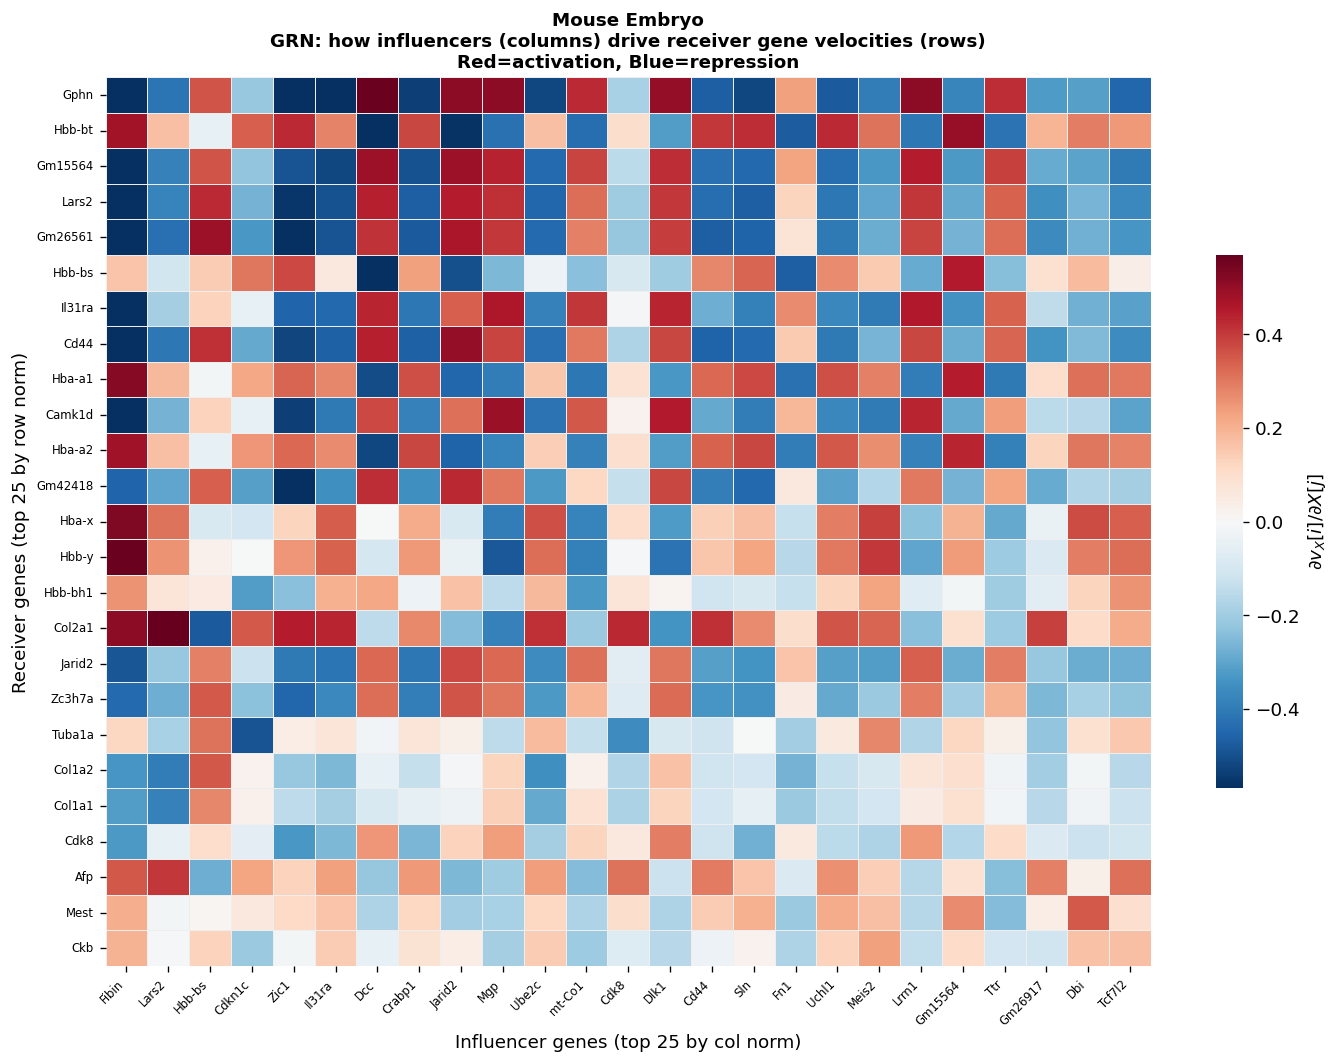

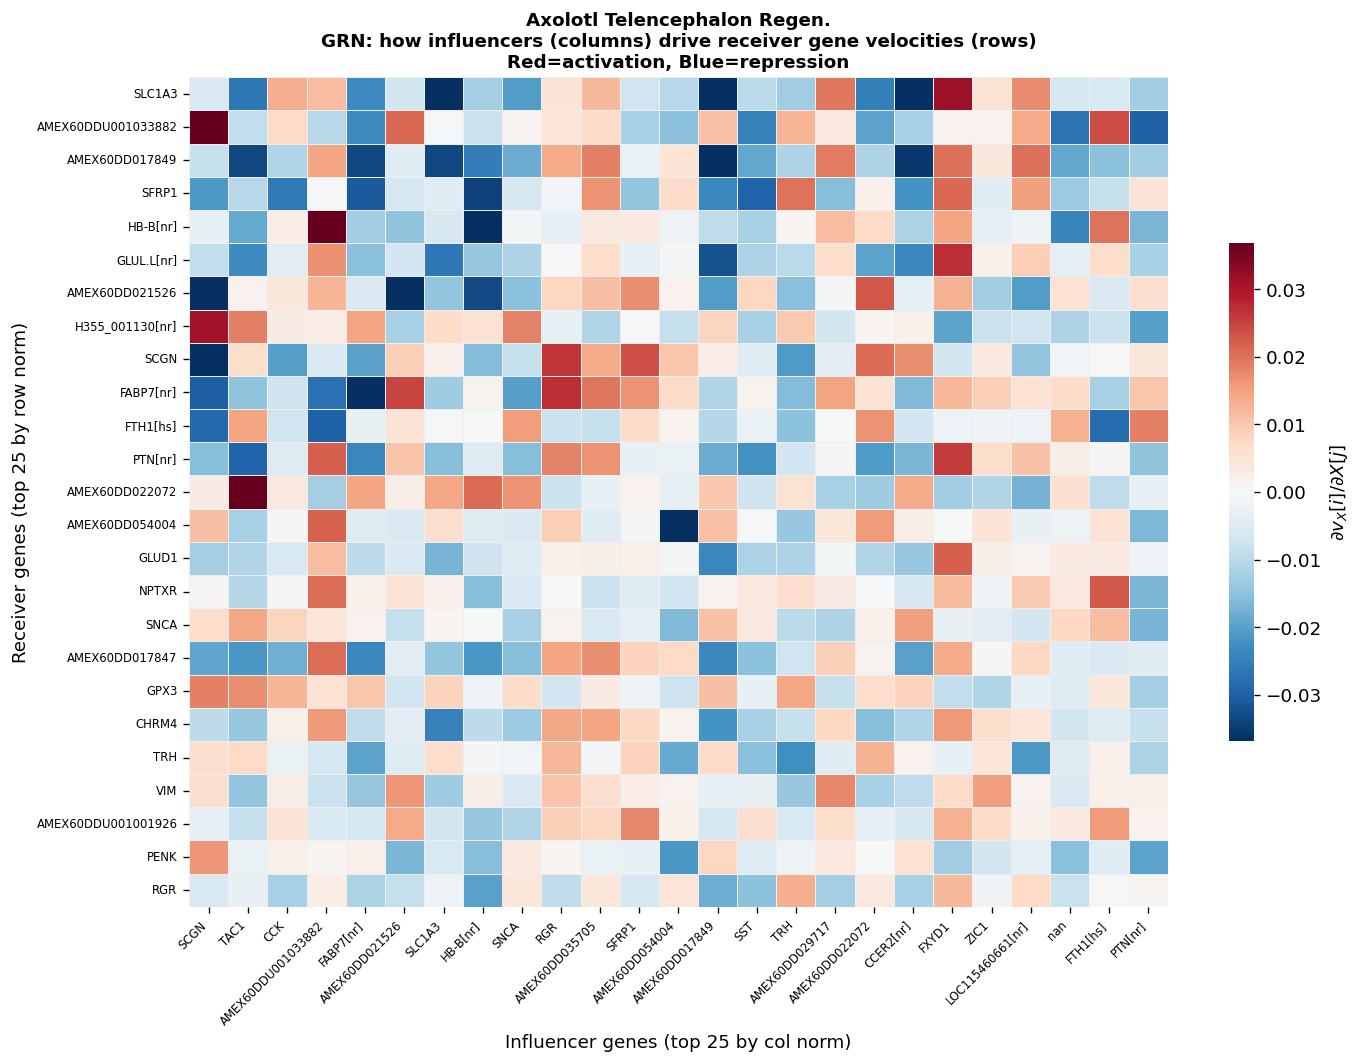

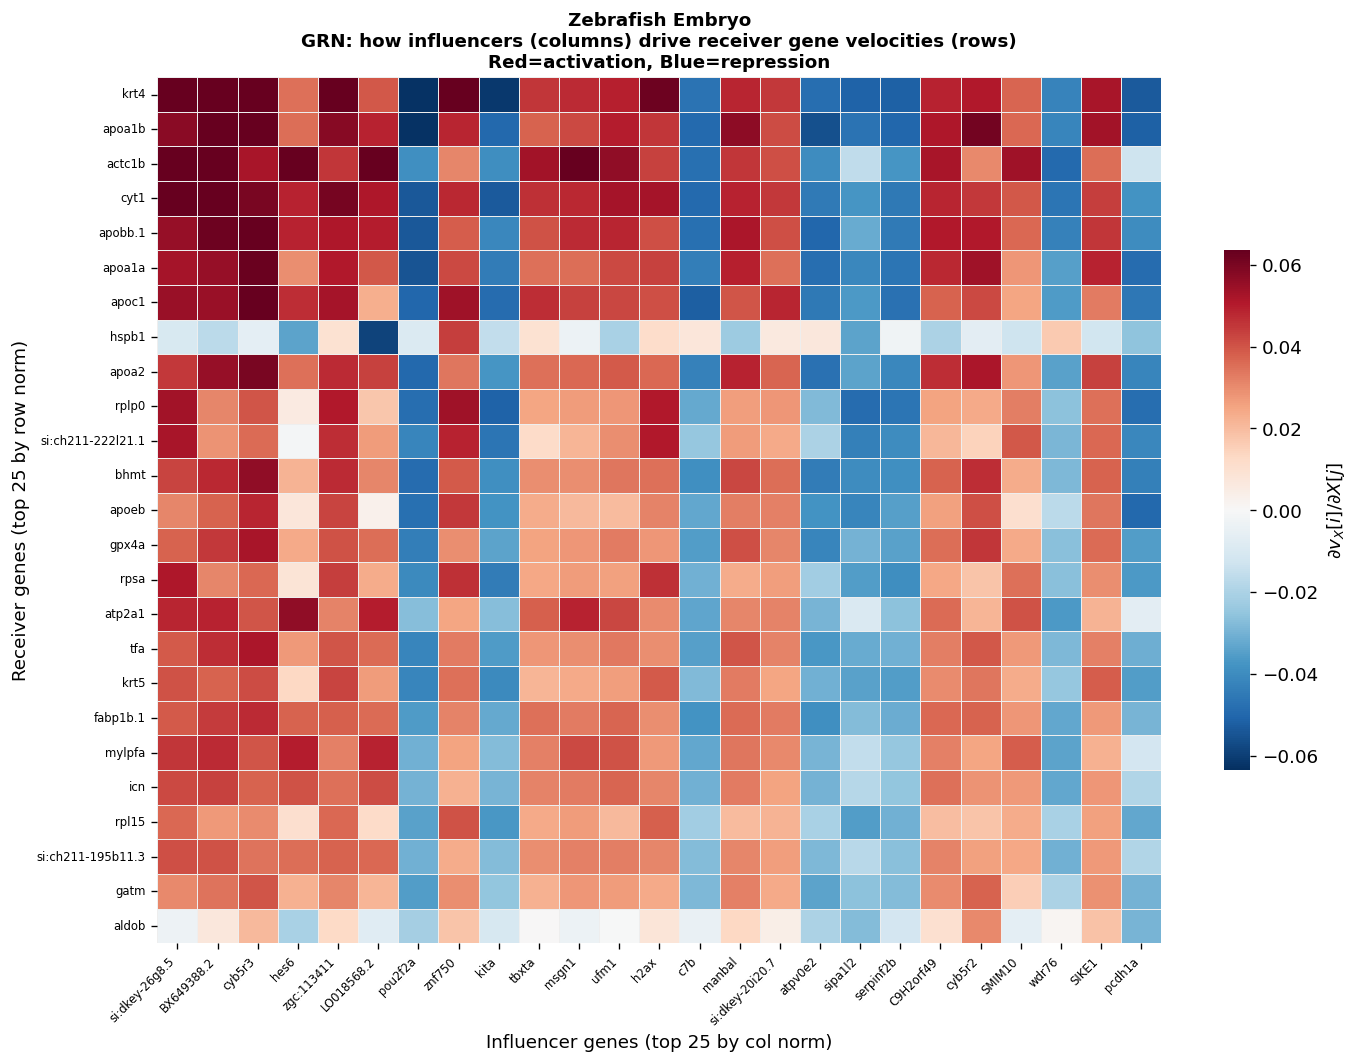

In [26]:
TOP_SUB = 25   # top N influencers and receivers for the submatrix

for dname, meta in DATASETS.items():
    GRN      = datasets[dname]['GRN']
    gene_df  = datasets[dname]['gene_df']

    top_inf = gene_df.nlargest(TOP_SUB, 'col_norm')
    top_rec = gene_df.nlargest(TOP_SUB, 'row_norm')

    inf_idx = top_inf['grn_idx'].values   # GRN column indices
    rec_idx = top_rec['grn_idx'].values   # GRN row indices
    inf_names = top_inf['gene_short'].values
    rec_names = top_rec['gene_short'].values

    sub = GRN[np.ix_(rec_idx, inf_idx)]   # (receivers, influencers)
    vmax = np.percentile(np.abs(sub), 98)

    fig, ax = plt.subplots(figsize=(12, 9))
    sns.heatmap(
        sub,
        ax=ax,
        cmap='RdBu_r',
        center=0, vmin=-vmax, vmax=vmax,
        xticklabels=inf_names,
        yticklabels=rec_names,
        linewidths=0.3, linecolor='#eeeeee',
        cbar_kws={'label': r'$\partial v_X[i] / \partial X[j]$', 'shrink': 0.6},
    )
    ax.set_xlabel(f'Influencer genes (top {TOP_SUB} by col norm)', fontsize=11)
    ax.set_ylabel(f'Receiver genes (top {TOP_SUB} by row norm)', fontsize=11)
    ax.set_title(
        f"{meta['label']}\nGRN: how influencers (columns) drive receiver gene velocities (rows)\n"
        r'Red=activation, Blue=repression',
        fontsize=11, fontweight='bold'
    )
    ax.tick_params(axis='x', labelsize=7, rotation=45)
    ax.set_xticklabels(ax.get_xticklabels(), ha='right')
    ax.tick_params(axis='y', labelsize=7)
    plt.tight_layout()
    plt.savefig(f"{BIO_DIR}/{DATASETS[dname]['dir']}/GRN_sub_heatmap.png", dpi=300, bbox_inches='tight')
    plt.show()

## 5. Regulatory Network Graph

Node size = column norm (influence strength); node color = red for influencer, blue for receiver, purple for hub.  
Edge color = red for activation (positive value) and blue for inhibition (negative value).

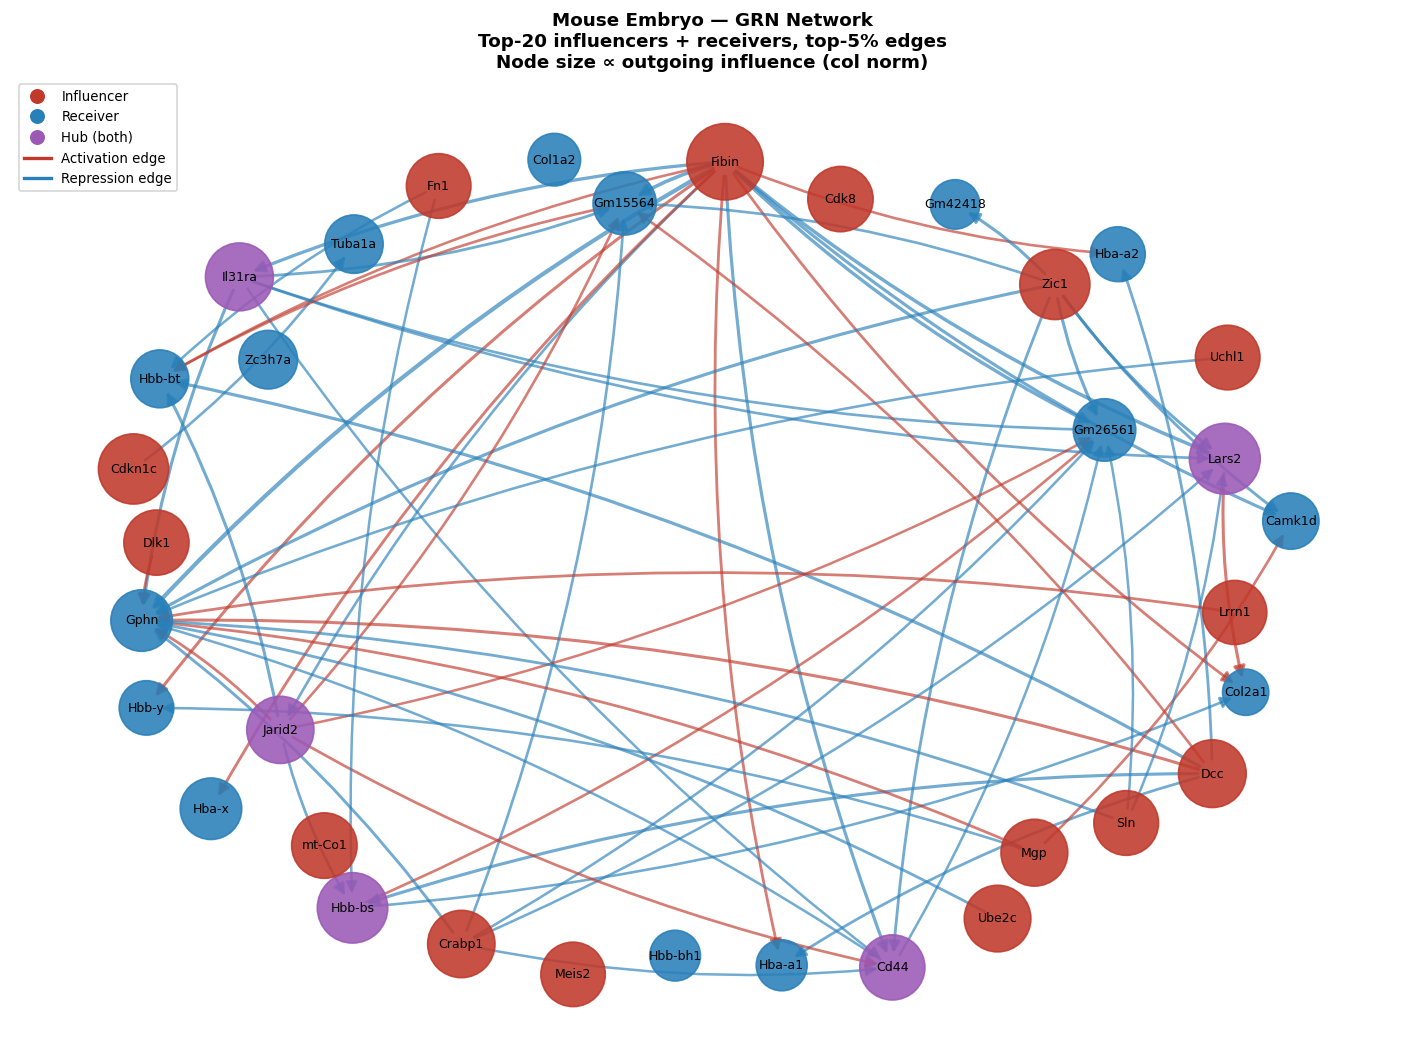

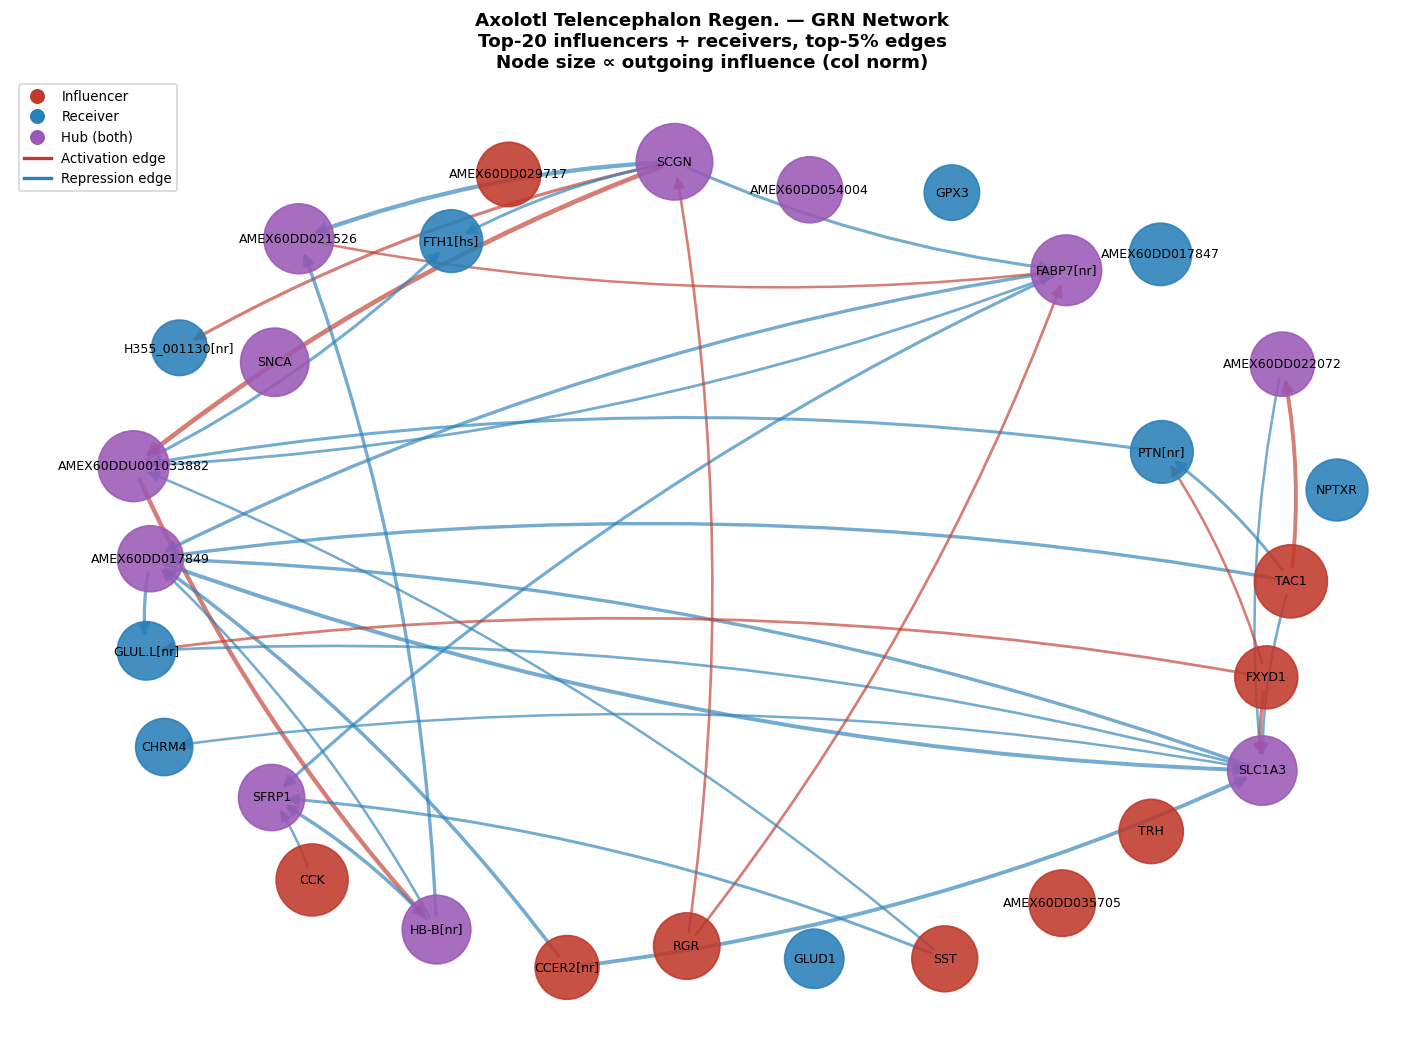

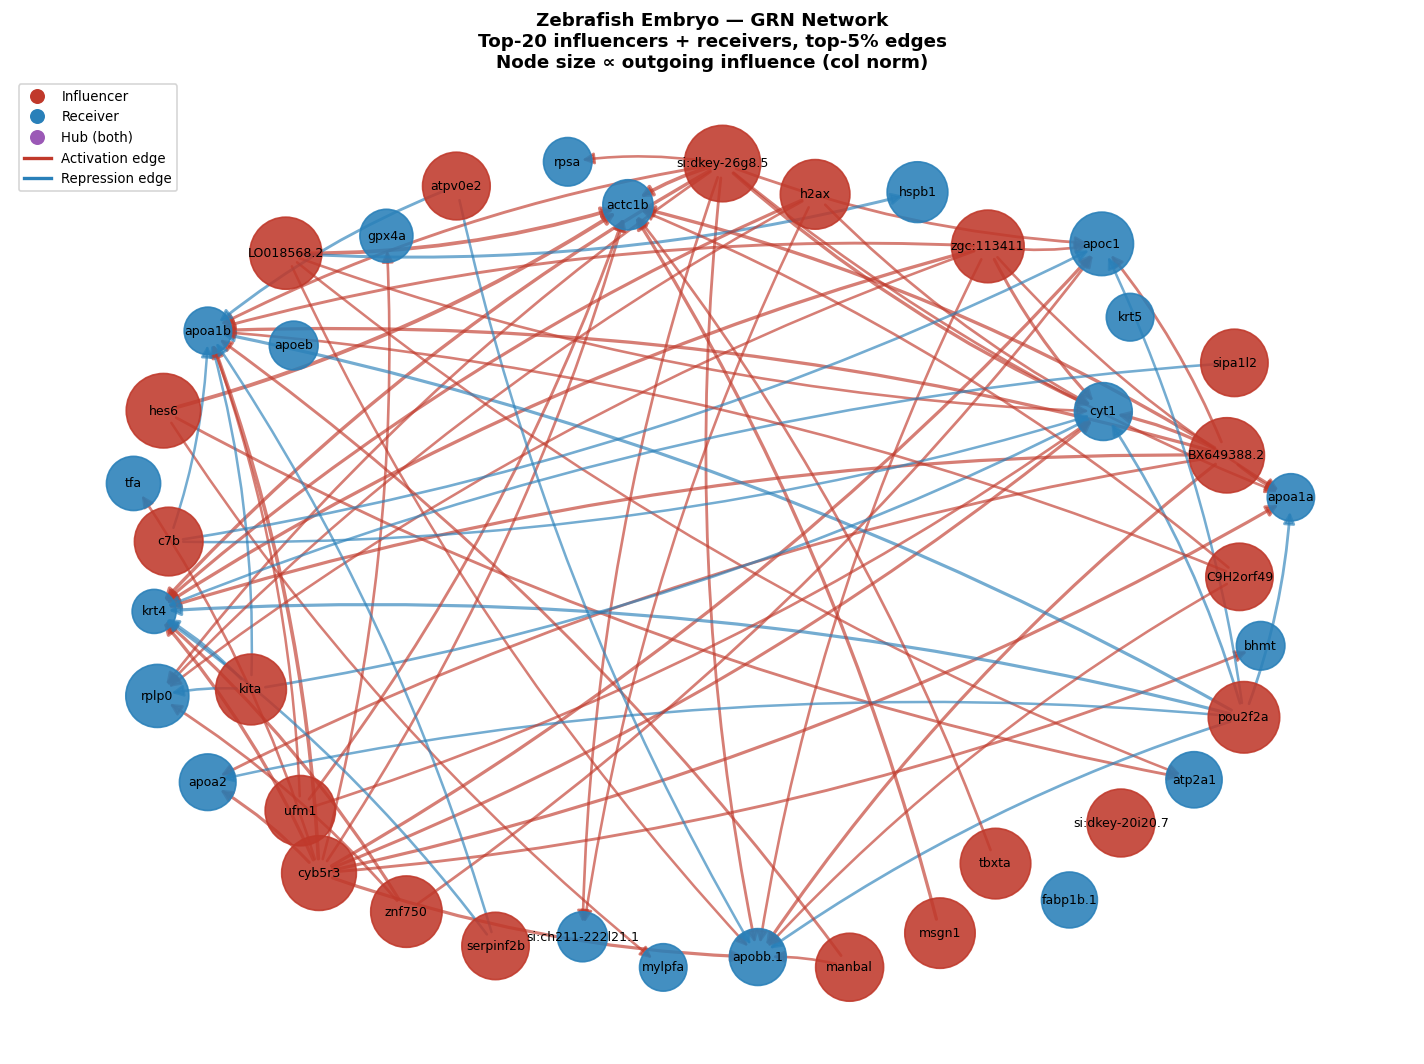

In [27]:
TOP_NET = 20        # top N influencers + top N receivers
EDGE_PCTILE = 95    # threshold: keep top-X% edges within the submatrix

for dname, meta in DATASETS.items():
    GRN     = datasets[dname]['GRN']
    gene_df = datasets[dname]['gene_df']

    top_inf_df = gene_df.nlargest(TOP_NET, 'col_norm')
    top_rec_df = gene_df.nlargest(TOP_NET, 'row_norm')

    # Union of influencer and receiver genes
    union_idx = list(dict.fromkeys(
        top_inf_df['grn_idx'].tolist() + top_rec_df['grn_idx'].tolist()
    ))
    sub_gene_df = gene_df[gene_df['grn_idx'].isin(union_idx)].copy()

    inf_set = set(top_inf_df['grn_idx'])
    rec_set = set(top_rec_df['grn_idx'])

    # Submatrix for these genes
    sub_grn = GRN[np.ix_(union_idx, union_idx)]
    thresh  = np.percentile(np.abs(sub_grn[sub_grn != 0]), EDGE_PCTILE)

    G = nx.DiGraph()
    for local_i, gi in enumerate(union_idx):
        G.add_node(gi)
    for local_i, gi in enumerate(union_idx):
        for local_j, gj in enumerate(union_idx):
            if gi != gj:
                w = sub_grn[local_i, local_j]  # GRN[receiver, influencer]
                if abs(w) >= thresh:
                    G.add_edge(gj, gi, weight=w)  # edge: influencer -> receiver

    pos = nx.spring_layout(G, seed=42, k=2.2)

    # Node attributes
    col_vals = sub_gene_df.set_index('grn_idx')['col_norm']
    max_col  = col_vals.max()
    node_sizes  = [300 + 1800 * col_vals.get(n, 0) / max_col for n in G.nodes()]
    node_colors = []
    for n in G.nodes():
        is_inf = n in inf_set
        is_rec = n in rec_set
        if is_inf and is_rec: node_colors.append('#9b59b6')   # Hub: purple
        elif is_inf:          node_colors.append('#c0392b')   # Influencer: red
        else:                 node_colors.append('#2980b9')   # Receiver: blue

    edge_colors = ['#c0392b' if G[u][v]['weight'] > 0 else '#2980b9'
                   for u, v in G.edges()]
    edge_widths = [min(abs(G[u][v]['weight']) / thresh * 1.5, 3.5)
                   for u, v in G.edges()]

    labels = {n: sub_gene_df.set_index('grn_idx')['gene_short'].get(n, str(n))
               for n in G.nodes()}

    fig, ax = plt.subplots(figsize=(12, 9))
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=node_sizes,
                           node_color=node_colors, alpha=0.88)
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=edge_colors,
                           width=edge_widths, arrows=True, arrowsize=14,
                           alpha=0.65, connectionstyle='arc3,rad=0.08')
    nx.draw_networkx_labels(G, pos, ax=ax, labels=labels, font_size=7.5)

    # Legend
    from matplotlib.lines import Line2D
    legend_els = [
        Line2D([0],[0], marker='o', color='w', markerfacecolor='#c0392b', ms=10, label='Influencer'),
        Line2D([0],[0], marker='o', color='w', markerfacecolor='#2980b9', ms=10, label='Receiver'),
        Line2D([0],[0], marker='o', color='w', markerfacecolor='#9b59b6', ms=10, label='Hub (both)'),
        Line2D([0],[0], color='#c0392b', lw=2, label='Activation edge'),
        Line2D([0],[0], color='#2980b9', lw=2, label='Repression edge'),
    ]
    ax.legend(handles=legend_els, fontsize=8, loc='upper left')
    ax.set_title(
        f"{meta['label']} — GRN Network\n"
        f"Top-{TOP_NET} influencers + receivers, top-{100-EDGE_PCTILE}% edges\n"
        f"Node size ∝ outgoing influence (col norm)",
        fontsize=11, fontweight='bold'
    )
    ax.axis('off')
    plt.tight_layout()
    plt.savefig(f"{BIO_DIR}/{DATASETS[dname]['dir']}/GRN_network.png", dpi=300, bbox_inches='tight')
    plt.show()

## 6. Activation/Inhibition Output Distribution for Each Influencer

In the GRN, the regulatory effect from gene j to gene i is positive for activation (increasing v_X[i]) and negative for inhibition (decreasing v_X[i]).  
This section analyzes the proportion and magnitude of activating vs. inhibiting outgoing edges for each top influencer.

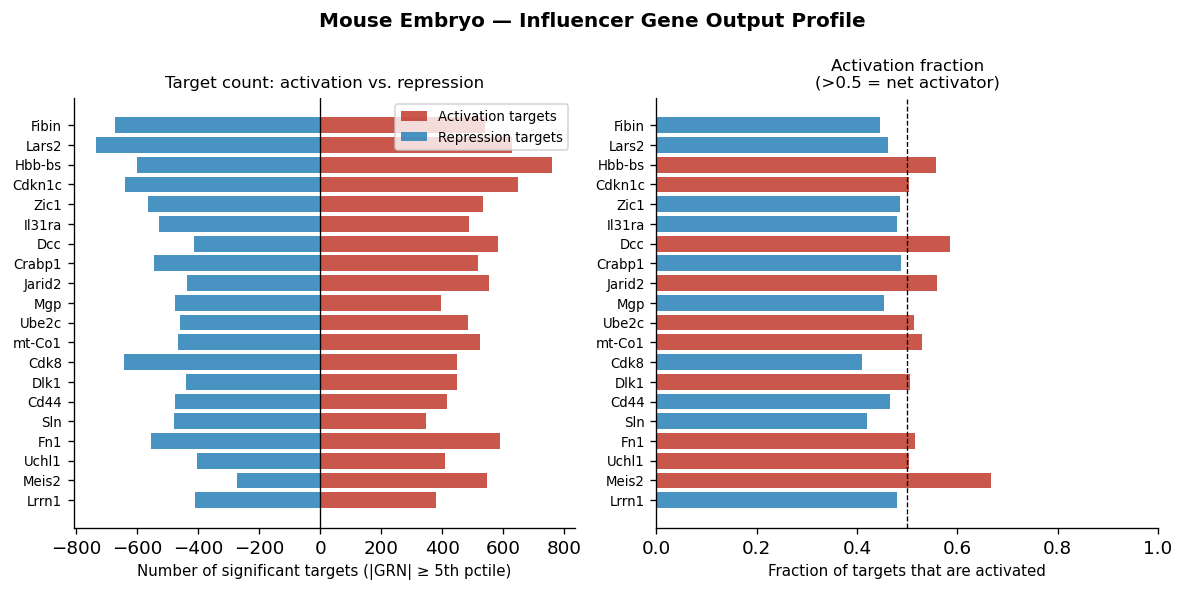


Mouse Embryo:
  gene  col_norm  n_activation  n_repression  frac_activation
 Fibin  3.267126           542           674         0.445724
 Lars2  2.731297           628           734         0.461087
Hbb-bs  2.695522           761           602         0.558327
Cdkn1c  2.675241           650           641         0.503486
  Zic1  2.667508           534           564         0.486339
Il31ra  2.465015           489           529         0.480354
   Dcc  2.451633           584           413         0.585757
Crabp1  2.418176           517           544         0.487276
Jarid2  2.406088           553           437         0.558586
   Mgp  2.372111           395           475         0.454023
 Ube2c  2.353863           485           460         0.513228
mt-Co1  2.256011           524           465         0.529828
  Cdk8  2.241305           449           644         0.410796
  Dlk1  2.229649           450           441         0.505051
  Cd44  2.227507           415           477         0.

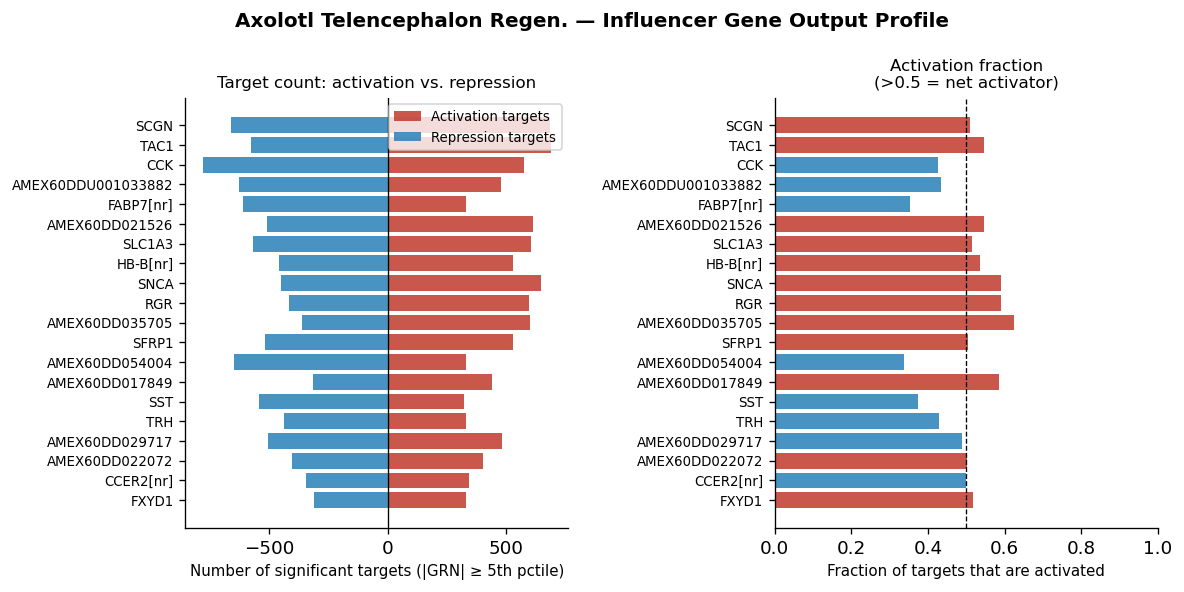


Axolotl Telencephalon Regen.:
              gene  col_norm  n_activation  n_repression  frac_activation
              SCGN  0.225897           687           661         0.509644
              TAC1  0.203462           691           576         0.545383
               CCK  0.195885           579           783         0.425110
AMEX60DDU001033882  0.188615           482           629         0.433843
         FABP7[nr]  0.187216           334           612         0.353066
    AMEX60DD021526  0.182655           614           511         0.545778
            SLC1A3  0.179261           606           570         0.515306
          HB-B[nr]  0.175045           531           459         0.536364
              SNCA  0.172693           651           452         0.590209
               RGR  0.161344           599           416         0.590148
    AMEX60DD035705  0.161216           605           364         0.624355
             SFRP1  0.160000           529           520         0.504290
    AME

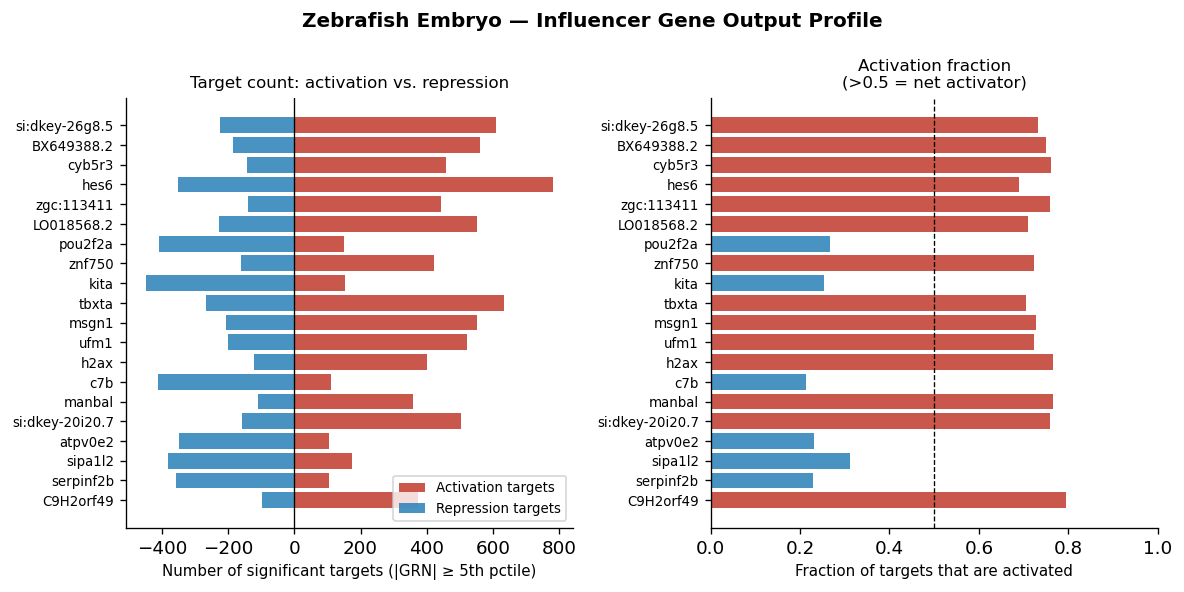


Zebrafish Embryo:
           gene  col_norm  n_activation  n_repression  frac_activation
 si:dkey-26g8.5  0.376290           611           224         0.731737
     BX649388.2  0.362777           562           187         0.750334
         cyb5r3  0.357195           458           143         0.762063
           hes6  0.354482           781           353         0.688713
     zgc:113411  0.334113           444           141         0.758974
     LO018568.2  0.327881           552           227         0.708601
        pou2f2a  0.321238           149           411         0.266071
         znf750  0.320849           423           162         0.723077
           kita  0.314081           152           449         0.252912
          tbxta  0.311478           635           266         0.704772
          msgn1  0.309984           553           207         0.727632
           ufm1  0.309002           521           200         0.722607
           h2ax  0.301602           401           123     

In [28]:
TOP_INF_ACT = 20
THRESH_PCTILE = 95

for dname, meta in DATASETS.items():
    GRN     = datasets[dname]['GRN']
    gene_df = datasets[dname]['gene_df']
    thresh  = np.percentile(np.abs(GRN), THRESH_PCTILE)

    top_inf = gene_df.nlargest(TOP_INF_ACT, 'col_norm')

    rows = []
    for _, gene_row in top_inf.iterrows():
        j = gene_row['grn_idx']
        col = GRN[:, j].copy()
        col[j] = 0   # exclude self
        sig = col[np.abs(col) >= thresh]
        n_act = (sig > 0).sum()
        n_rep = (sig < 0).sum()
        sum_act = sig[sig > 0].sum()
        sum_rep = sig[sig < 0].sum()
        rows.append({
            'gene': gene_row['gene_short'],
            'col_norm': gene_row['col_norm'],
            'n_activation': n_act,
            'n_repression': n_rep,
            'sum_activation': sum_act,
            'sum_repression': sum_rep,
            'frac_activation': n_act / max(n_act + n_rep, 1),
        })
    act_df = pd.DataFrame(rows).sort_values('col_norm', ascending=True)

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    # Stacked bar: n_activation and n_repression
    ax = axes[0]
    y = np.arange(len(act_df))
    ax.barh(y, act_df['n_activation'], color='#c0392b', label='Activation targets', alpha=0.85)
    ax.barh(y, -act_df['n_repression'], color='#2980b9', label='Repression targets', alpha=0.85)
    ax.axvline(0, color='k', lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels(act_df['gene'], fontsize=8)
    ax.set_xlabel(f'Number of significant targets (|GRN| ≥ {100-THRESH_PCTILE}th pctile)', fontsize=9)
    ax.set_title('Target count: activation vs. repression', fontsize=10)
    ax.legend(fontsize=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Fraction activation
    ax = axes[1]
    colors_frac = [('#c0392b' if f >= 0.5 else '#2980b9') for f in act_df['frac_activation']]
    ax.barh(y, act_df['frac_activation'], color=colors_frac, alpha=0.85)
    ax.axvline(0.5, color='k', lw=0.8, ls='--')
    ax.set_xlim(0, 1)
    ax.set_yticks(y)
    ax.set_yticklabels(act_df['gene'], fontsize=8)
    ax.set_xlabel('Fraction of targets that are activated', fontsize=9)
    ax.set_title('Activation fraction\n(>0.5 = net activator)', fontsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.suptitle(f"{meta['label']} — Influencer Gene Output Profile",
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{BIO_DIR}/{DATASETS[dname]['dir']}/influencer_activation_profile.png", dpi=300, bbox_inches='tight')
    plt.show()

    print(f"\n{meta['label']}:")
    print(act_df[['gene','col_norm','n_activation','n_repression','frac_activation']]
          .sort_values('col_norm', ascending=False)
          .to_string(index=False))

## 7. Influencer/Receiver Overlap Analysis: Hub Gene Identification


Mouse Embryo — Hub genes (top-50 in both influencer & receiver):
         gene  outgoing  incoming  hub_score  self_reg
        Lars2  2.731297  4.477973  12.230675 -0.379023
       Hbb-bs  2.695522  4.356103  11.741971  0.145760
       Il31ra  2.465015  4.327478  10.667300 -0.448493
         Gphn  1.927191  5.187269   9.996857  0.277462
         Cd44  2.227507  4.259271   9.487554 -0.459481
      Gm15564  2.068223  4.554768   9.420274 -0.328022
      Gm26561  2.004220  4.446455   8.911674  0.055171
       Jarid2  2.406088  3.603503   8.670346  0.376167
        Hba-x  1.927559  3.982723   7.676933  0.342210
         Cdk8  2.241305  2.660893   5.963874  0.058587
       Crabp1  2.418176  2.107165   5.095496 -0.115448
       Cdkn1c  2.675241  1.893864   5.066544 -0.021070
         Nnat  1.995604  2.411858   4.813113  0.086498
        Uchl1  2.180255  1.930340   4.208633  0.063502
        Rps21  1.768203  2.340874   4.139140 -0.085464
         Gpx1  1.826709  2.131059   3.892825  0.054263

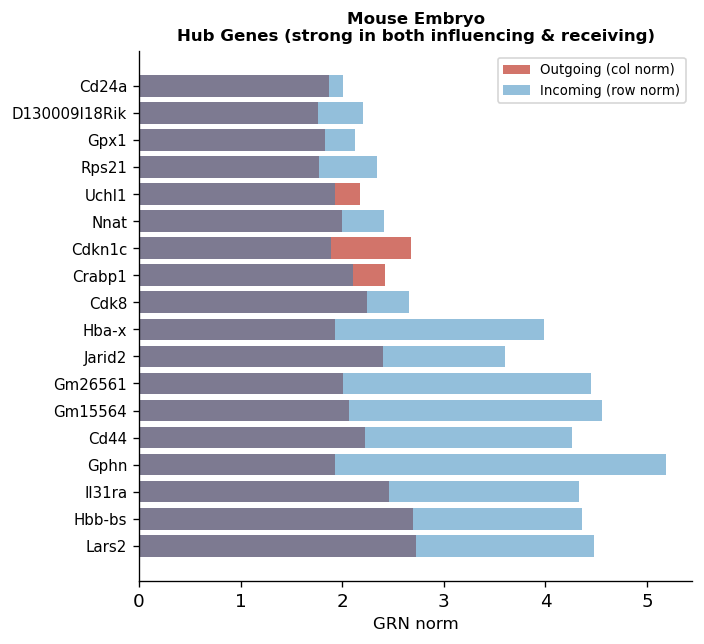


Axolotl Telencephalon Regen. — Hub genes (top-50 in both influencer & receiver):
              gene  outgoing  incoming  hub_score  self_reg
AMEX60DDU001033882  0.188615  0.404409   0.076278 -0.010349
            SLC1A3  0.179261  0.406102   0.072798 -0.039692
              SCGN  0.225897  0.304921   0.068881 -0.040414
          HB-B[nr]  0.175045  0.343330   0.060098 -0.050337
    AMEX60DD021526  0.182655  0.322884   0.058976 -0.049778
         FABP7[nr]  0.187216  0.304048   0.056923 -0.050536
             SFRP1  0.160000  0.355589   0.056894 -0.014542
    AMEX60DD017849  0.158718  0.357347   0.056718 -0.040064
              SNCA  0.172693  0.256776   0.044343 -0.012126
    AMEX60DD054004  0.159447  0.274702   0.043801 -0.041481
    AMEX60DD022072  0.147967  0.295807   0.043770 -0.012960
          FTH1[hs]  0.139270  0.300843   0.041898 -0.027943
           PTN[nr]  0.139059  0.300313   0.041761 -0.014753
              TAC1  0.203462  0.197934   0.040272 -0.017470
               RGR

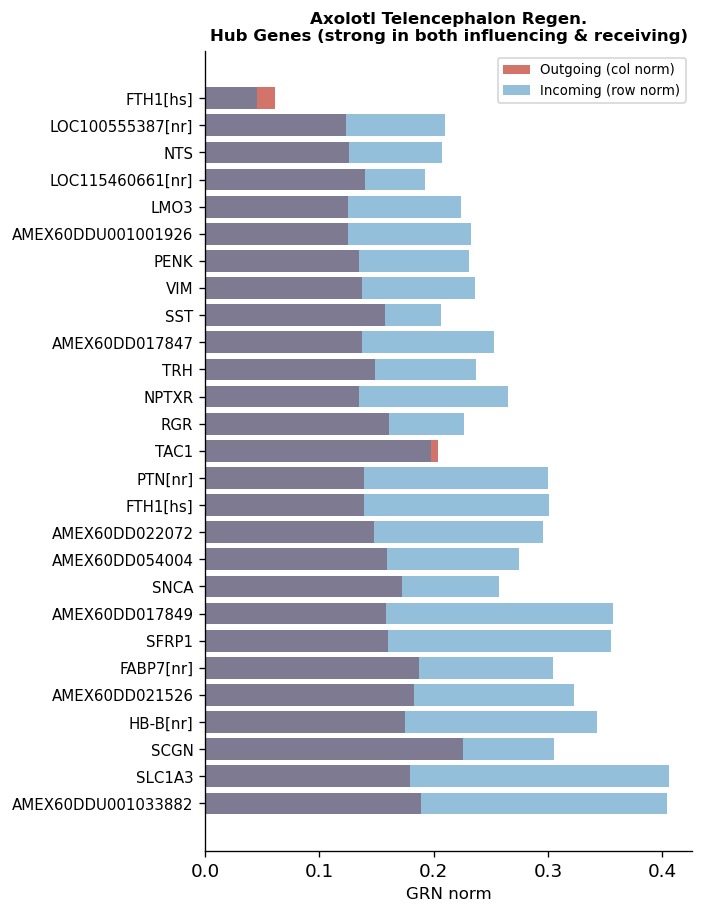


Zebrafish Embryo — Hub genes (top-50 in both influencer & receiver):
Empty DataFrame
Columns: [gene, outgoing, incoming, hub_score, self_reg]
Index: []


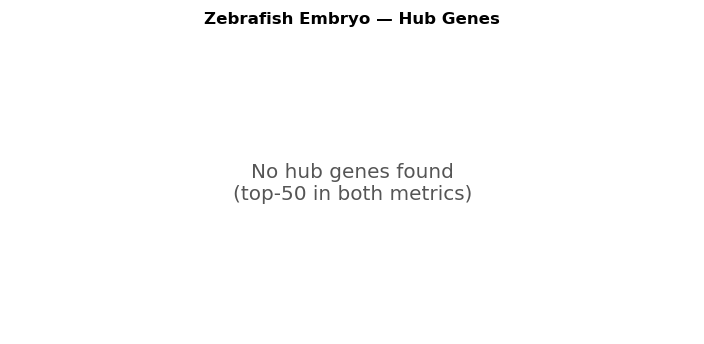

In [29]:
TOP_RANK = 50   # consider top-N in each metric

for dname, meta in DATASETS.items():
    gene_df = datasets[dname]['gene_df'].copy()
    gene_df['col_rank'] = gene_df['col_norm'].rank(ascending=False)
    gene_df['row_rank'] = gene_df['row_norm'].rank(ascending=False)
    gene_df['hub_score'] = gene_df['col_norm'] * gene_df['row_norm']   # geometric importance

    top_inf_set = set(gene_df.nlargest(TOP_RANK, 'col_norm')['gene_short'])
    top_rec_set = set(gene_df.nlargest(TOP_RANK, 'row_norm')['gene_short'])
    hubs = top_inf_set & top_rec_set

    hub_df = gene_df[gene_df['gene_short'].isin(hubs)].sort_values('hub_score', ascending=False)

    print(f"\n{meta['label']} — Hub genes (top-{TOP_RANK} in both influencer & receiver):")
    print(hub_df[['gene_short','col_norm','row_norm','hub_score','self_reg']]
          .rename(columns={'gene_short':'gene','col_norm':'outgoing','row_norm':'incoming','hub_score':'hub_score','self_reg':'self_reg'})
          .to_string(index=False))

    if len(hub_df) > 0:
        fig, ax = plt.subplots(figsize=(6, max(3, len(hub_df)*0.25 + 1)))
        y = np.arange(len(hub_df))
        ax.barh(y, hub_df['col_norm'], color='#c0392b', alpha=0.7, label='Outgoing (col norm)')
        ax.barh(y, hub_df['row_norm'], color='#2980b9', alpha=0.5, label='Incoming (row norm)')
        ax.set_yticks(y)
        ax.set_yticklabels(hub_df['gene_short'], fontsize=9)
        ax.set_xlabel('GRN norm', fontsize=10)
        ax.set_title(f"{meta['label']}\nHub Genes (strong in both influencing & receiving)",
                     fontsize=10, fontweight='bold')
        ax.legend(fontsize=8)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        plt.tight_layout()
        plt.savefig(f"{BIO_DIR}/{DATASETS[dname]['dir']}/hub_genes.png", dpi=300, bbox_inches='tight')
        plt.show()
    
    # if no hubs, show no hub in the same plot
    else:
        fig, ax = plt.subplots(figsize=(6, 3))
        ax.text(0.5, 0.5, 'No hub genes found\n(top-50 in both metrics)', fontsize=12,
                ha='center', va='center', color='#555555')
        ax.set_title(f"{meta['label']} — Hub Genes", fontsize=10, fontweight='bold')
        ax.axis('off')
        plt.tight_layout()
        plt.savefig(f"{BIO_DIR}/{DATASETS[dname]['dir']}/hub_genes.png", dpi=300, bbox_inches='tight')
        plt.show()

## 8. GO Enrichment Analysis (Top Influencers and Top Receivers)

Requires `pip install gprofiler-official` and an active network connection.


=== Mouse Embryo ===


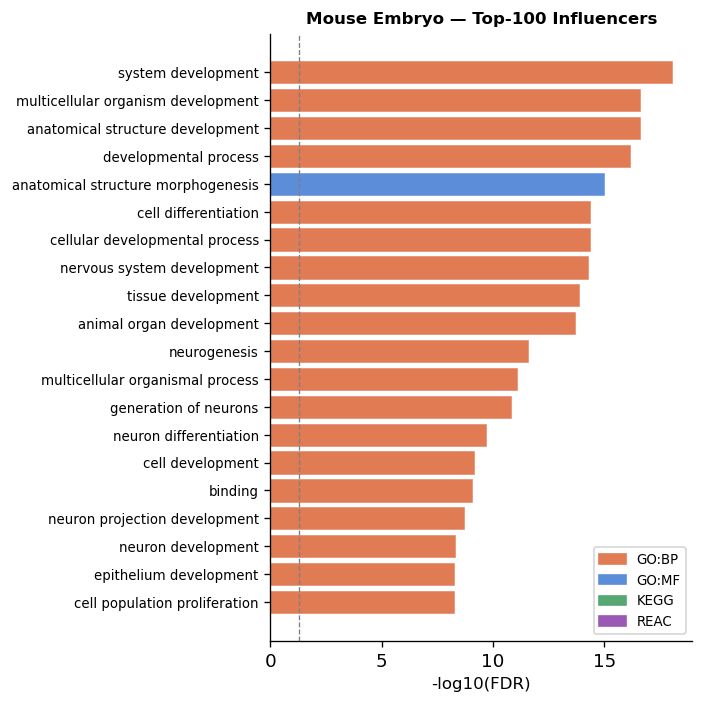

  Mouse Embryo — Top-100 Influencers: 880 terms, top=system development


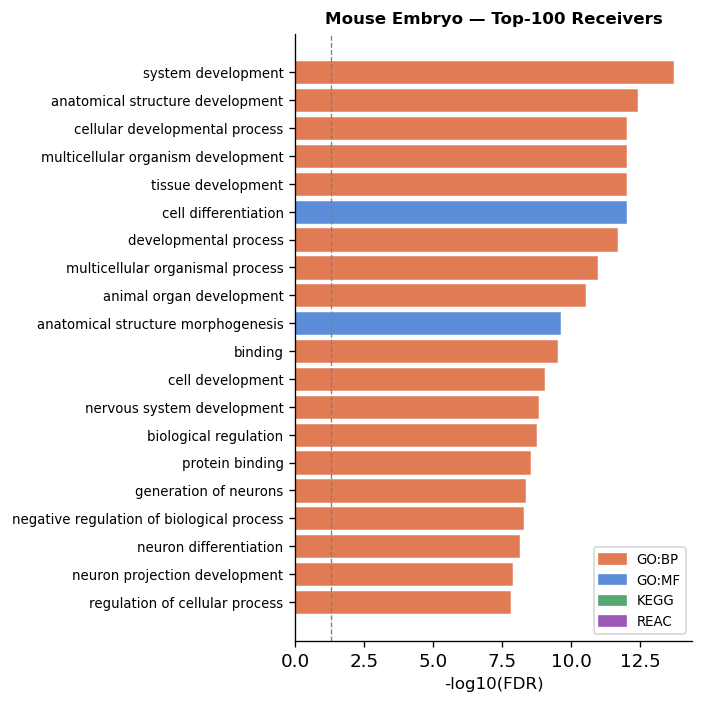

  Mouse Embryo — Top-100 Receivers: 687 terms, top=system development

=== Axolotl Telencephalon Regen. ===


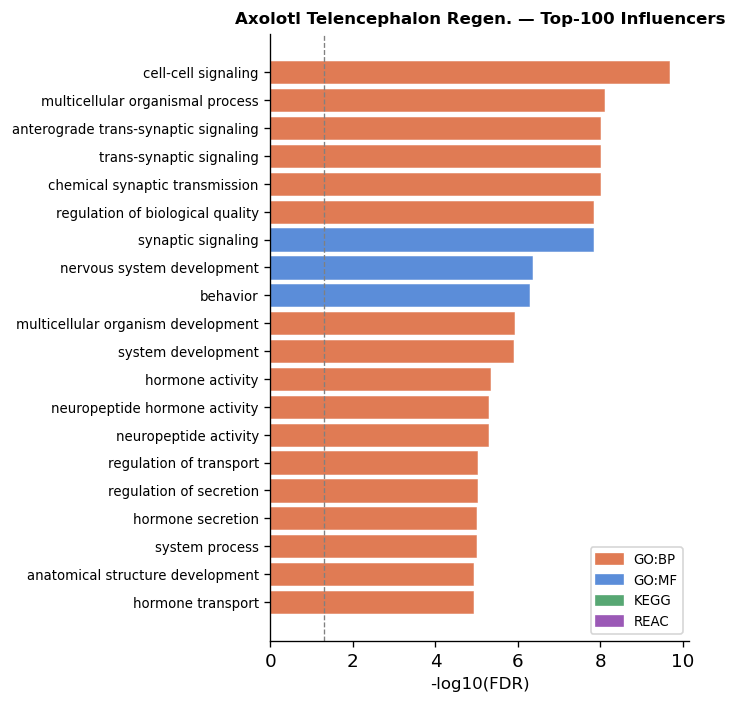

  Axolotl Telencephalon Regen. — Top-100 Influencers: 397 terms, top=cell-cell signaling


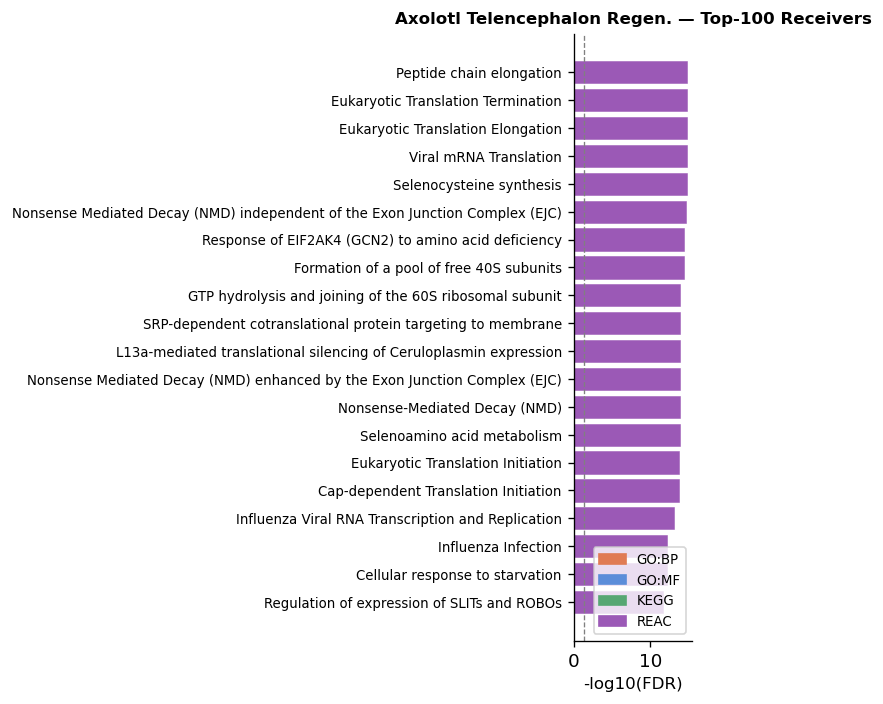

  Axolotl Telencephalon Regen. — Top-100 Receivers: 338 terms, top=Peptide chain elongation

=== Zebrafish Embryo ===


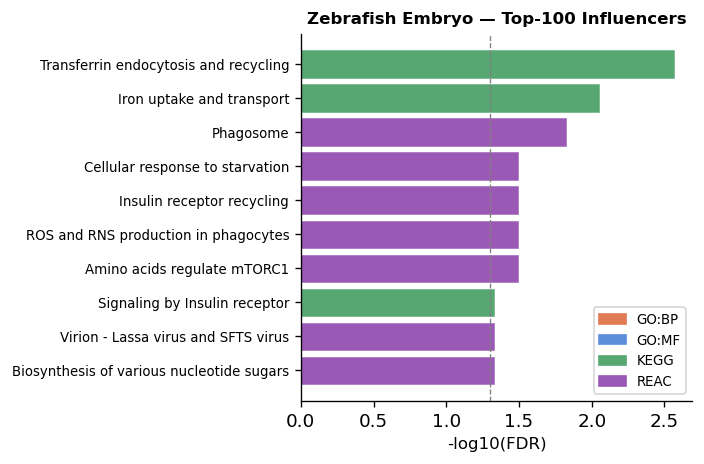

  Zebrafish Embryo — Top-100 Influencers: 10 terms, top=Transferrin endocytosis and recycling


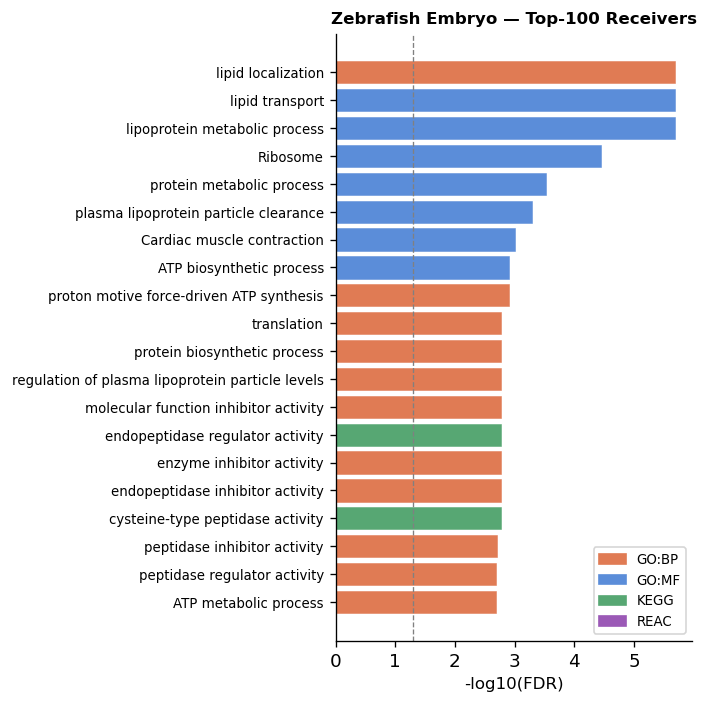

  Zebrafish Embryo — Top-100 Receivers: 146 terms, top=lipid localization


In [30]:
TOP_ENRICH = 100
SPECIES_MAP = {'mouse': 'mmusculus', 'axoltl': 'hsapiens', 'zebrafish': 'drerio'}

try:
    from gprofiler import GProfiler
    gp = GProfiler(return_dataframe=True)

    def run_enrichment(gene_list, organism, label, color, save_path):
        res = gp.profile(
            query=gene_list,
            organism=organism,
            sources=['GO:BP', 'GO:MF', 'KEGG', 'REAC'],
            significance_threshold_method='fdr',
            user_threshold=0.05,
        )
        if len(res) == 0:
            print(f'  {label}: no significant terms')
            return
        res.to_csv(save_path.replace('.png', '.csv'), index=False)
        top_res = res.head(20).iloc[::-1]
        fig, ax = plt.subplots(figsize=(6, max(4, len(top_res)*0.25 + 1)))
        bars = ax.barh(top_res['name'], -np.log10(top_res['p_value']),
                       color=color, edgecolor='white', linewidth=0.3)
        ax.axvline(-np.log10(0.05), color='gray', ls='--', lw=0.8, label='p=0.05')
        # Color by source
        src_colors = {'GO:BP':'#e07b54','GO:MF':'#5b8dd9','KEGG':'#57a773','REAC':'#9b59b6'}
        for bar, src in zip(bars, top_res['source'].iloc[::-1]):
            bar.set_color(src_colors.get(src, color))
        from matplotlib.patches import Patch
        ax.legend(handles=[Patch(color=v, label=k) for k, v in src_colors.items()],
                  fontsize=8, loc='lower right')
        ax.set_xlabel('-log10(FDR)', fontsize=10)
        ax.set_title(label, fontsize=10, fontweight='bold')
        ax.tick_params(axis='y', labelsize=8)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        plt.tight_layout()
        plt.savefig(save_path, bbox_inches='tight', dpi=300)
        plt.show()
        print(f'  {label}: {len(res)} terms, top={res.iloc[0]["name"]}')

    for dname, meta in DATASETS.items():
        gene_df  = datasets[dname]['gene_df']
        organism = SPECIES_MAP[dname]
        d        = DATASETS[dname]['dir']

        def clean_names(df_sub):
            return [g.split('[')[0].strip() for g in df_sub['gene_short']]

        print(f"\n=== {meta['label']} ===")
        inf_genes = clean_names(gene_df.nlargest(TOP_ENRICH, 'col_norm'))
        rec_genes = clean_names(gene_df.nlargest(TOP_ENRICH, 'row_norm'))

        run_enrichment(inf_genes, organism,
                       f"{meta['label']} — Top-{TOP_ENRICH} Influencers",
                       meta['color'], f"{BIO_DIR}/{d}/go_influencers.png")
        run_enrichment(rec_genes, organism,
                       f"{meta['label']} — Top-{TOP_ENRICH} Receivers",
                       '#888888', f"{BIO_DIR}/{d}/go_receivers.png")

except ImportError:
    print("gprofiler-official not installed: pip install gprofiler-official")
    print("Or paste gene lists at: https://biit.cs.ut.ee/gprofiler/gost\n")
    for dname, meta in DATASETS.items():
        gene_df  = datasets[dname]['gene_df']
        organism = SPECIES_MAP[dname]
        inf_genes = gene_df.nlargest(TOP_ENRICH, 'col_norm')['gene_short'].tolist()
        rec_genes = gene_df.nlargest(TOP_ENRICH, 'row_norm')['gene_short'].tolist()
        print(f"\n{meta['label']} ({organism})")
        print(f"  Influencers: {' '.join(str(g).split('[')[0].strip() for g in inf_genes)}")
        print(f"  Receivers:   {' '.join(str(g).split('[')[0].strip() for g in rec_genes)}")

In [ ]:

from PIL import Image
def combine_images_horizontally(image_paths, save_path):
    images = [Image.open(p) for p in image_paths]
    heights = [img.height for img in images]
    max_height = max(heights)
    resized_images = []
    for img in images:
        if img.height != max_height:
            new_width = int(img.width * (max_height / img.height))
            img = img.resize((new_width, max_height), resample=Image.LANCZOS)
        resized_images.append(img)
    total_width = sum(img.width for img in resized_images)
    combined_img = Image.new('RGB', (total_width, max_height), color=(255, 255, 255))
    x_offset = 0
    for img in resized_images:
        combined_img.paste(img, (x_offset, 0))
        x_offset += img.width
    combined_img.save(save_path)

combine_images_horizontally(
    [
        f"{BIO_DIR}/mouse/influencer_vs_receiver.png",
        f"{BIO_DIR}/mouse/hub_genes.png",
        f"{BIO_DIR}/mouse/go_influencers.png"
    ],
    f"{BIO_DIR}/mouse/mouse_summary.png"
)

In [ ]:
# combine plots
def combine_images_grid(image_paths, save_path):
    images = [Image.open(p) for p in image_paths]
    row1_imgs = images[0:3]
    row2_imgs = images[3:6]
    row3_imgs = images[6:8]
    def combine_row(imgs):
        heights = [img.height for img in imgs]
        max_height = max(heights)
        resized_imgs = []
        for img in imgs:
            if img.height != max_height:
                new_width = int(img.width * (max_height / img.height))
                img = img.resize((new_width, max_height), resample=Image.LANCZOS)
            resized_imgs.append(img)
        total_width = sum(img.width for img in resized_imgs)
        combined_img = Image.new('RGB', (total_width, max_height), color=(255, 255, 255))
        x_offset = 0
        for img in resized_imgs:
            combined_img.paste(img, (x_offset, 0))
            x_offset += img.width
        return combined_img
    row1 = combine_row(row1_imgs)
    row2 = combine_row(row2_imgs)
    row3 = combine_row(row3_imgs)
    max_width = max(row1.width, row2.width, row3.width)
    def resize_to_width(img, target_width):
        if img.width != target_width:
            new_height = int(img.height * (target_width / img.width))
            img = img.resize((target_width, new_height), resample=Image.LANCZOS)
        return img
    row1 = resize_to_width(row1, max_width)
    row2 = resize_to_width(row2, max_width)
    row3 = resize_to_width(row3, max_width)
    total_height = row1.height + row2.height + row3.height
    combined_img = Image.new('RGB', (max_width, total_height), color=(255, 255, 255))
    y_offset = 0
    for row in [row1, row2, row3]:
        combined_img.paste(row, (0, y_offset))
        y_offset += row.height
    combined_img.save(save_path)


combine_images_grid(
        [
            f"{BIO_DIR}/mouse/influencer_vs_receiver.png",
            f"{BIO_DIR}/mouse/top_influencers.png",
            f"{BIO_DIR}/mouse/top_receivers.png",
            f"{BIO_DIR}/mouse/hub_genes.png",
            f"{BIO_DIR}/mouse/go_influencers.png",
        f"{BIO_DIR}/mouse/go_receivers.png",
        f"{BIO_DIR}/mouse/GRN_sub_heatmap.png",
        f"{BIO_DIR}/mouse/influencer_activation_profile.png"
    ],
    f"{BIO_DIR}/mouse/mouse_full_summary.png"
)

combine_images_grid(
        [
            f"{BIO_DIR}/axoltl/influencer_vs_receiver.png",
            f"{BIO_DIR}/axoltl/top_influencers.png",
            f"{BIO_DIR}/axoltl/top_receivers.png",
            f"{BIO_DIR}/axoltl/hub_genes.png",
            f"{BIO_DIR}/axoltl/go_influencers.png",
        f"{BIO_DIR}/axoltl/go_receivers.png",
        f"{BIO_DIR}/axoltl/GRN_sub_heatmap.png",
        f"{BIO_DIR}/axoltl/influencer_activation_profile.png"
    ],
    f"{BIO_DIR}/axoltl/axoltl_full_summary.png"
)

combine_images_grid(
        [
            f"{BIO_DIR}/zebrafish/influencer_vs_receiver.png",
            f"{BIO_DIR}/zebrafish/top_influencers.png",
            f"{BIO_DIR}/zebrafish/top_receivers.png",
            f"{BIO_DIR}/zebrafish/hub_genes.png",
            f"{BIO_DIR}/zebrafish/go_influencers.png",
        f"{BIO_DIR}/zebrafish/go_receivers.png",
        f"{BIO_DIR}/zebrafish/GRN_sub_heatmap.png",
        f"{BIO_DIR}/zebrafish/influencer_activation_profile.png"
    ],
    f"{BIO_DIR}/zebrafish/zebrafish_full_summary.png"
)